# Predicting Disease Risk Level from DNA Sequence Features Using Machine Learning

## 0. Set-up

In [22]:
%matplotlib inline
import warnings
from collections import Counter
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mutual_info_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score,
                                     learning_curve, permutation_test_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

SEED = 42
TARGET = "Disease_Risk"
CLASS_ORDER_SKLEARN = ["High", "Low", "Medium"]
CLASS_ORDER_NATURAL = ["Low", "Medium", "High"]
SELECTED_FEATURES = ["GC_Content", "Num_A", "Num_C", "Mutation_Flag", "kmer_3_freq",
                     "Class_Human", "Class_Plant", "Class_Virus"]

FIGURE_FOLDER = Path("final_outputs/figures")
FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)

dna_data = pd.read_csv("/content/synthetic_dna_dataset.csv")
risk_labels = dna_data[TARGET].values
print(f"Loaded {len(dna_data):,} rows x {dna_data.shape[1]} columns")
display(dna_data.head())
display(dna_data.describe().round(2))

Loaded 3,000 rows x 13 columns


,Sample_ID,Sequence,GC_Content,AT_Content,Sequence_Length,Num_A,Num_T,Num_C,Num_G,kmer_3_freq,Mutation_Flag,Class_Label,Disease_Risk
0,SAMPLE_1,CTTTCGGGATACTTTTGGGATGGTCTTGGTCAAGGGTTTTAGCCCG...,50.0,50.0,100,22,28,19,31,0.986,0,Bacteria,High
1,SAMPLE_2,TTGACCAAATTTGATTGGAAGTGGTAAGCGCGTATTCCTAGCATCA...,45.0,55.0,100,27,28,22,23,0.486,1,Virus,Medium
2,SAMPLE_3,GCGTGAGTTCTAATTTAAAAAGTCGTAACACGTACCCCGGCGTGTA...,51.0,49.0,100,26,23,30,21,0.367,1,Bacteria,Low
3,SAMPLE_4,ACTACGCGGACAAGAACCAACAGAACCTGGTTTTCGCAAGGGAGTG...,55.0,45.0,100,28,17,23,32,0.404,0,Human,Medium
4,SAMPLE_5,TTCAATGCAGATTGAAAGTTACTTTCATCTGCCCTATGGGTCCCTT...,46.0,54.0,100,24,30,25,21,0.818,0,Human,High


,GC_Content,AT_Content,Sequence_Length,Num_A,Num_T,Num_C,Num_G,kmer_3_freq,Mutation_Flag
count,3000.00,3000.00,3000.0,3000.00,3000.00,3000.00,3000.00,3000.00,3000.0
mean,50.12,49.88,100.0,24.95,24.93,25.00,25.12,0.55,0.5
std,5.06,5.06,0.0,4.32,4.32,4.35,4.33,0.26,0.5
min,34.00,34.00,100.0,11.00,9.00,10.00,12.00,0.10,0.0
25%,47.00,47.00,100.0,22.00,22.00,22.00,22.00,0.33,0.0
50%,50.00,50.00,100.0,25.00,25.00,25.00,25.00,0.54,0.0
75%,53.00,53.00,100.0,28.00,28.00,28.00,28.00,0.77,1.0
max,66.00,66.00,100.0,40.00,42.00,42.00,42.00,1.00,1.0


# Part 1 - Exploratory Data Analysis

In [23]:
column_overview = pd.DataFrame({"dtype": dna_data.dtypes.astype(str),
                                "missing_pct": dna_data.isna().mean() * 100,
                                "unique_values": dna_data.nunique()})
display(column_overview)
print(f"Missing values: {int(dna_data.isna().sum().sum())} | duplicate rows: {int(dna_data.duplicated().sum())}")

class_counts = dna_data[TARGET].value_counts().reindex(CLASS_ORDER_NATURAL)
balance_test = stats.chisquare(class_counts.values)
majority_baseline = class_counts.max() / class_counts.sum()
print(f"Target counts (Low / Medium / High): {class_counts.tolist()}")
print(f"Goodness of fit to 1/3 each: p = {balance_test.pvalue:.2f}")
print(f"Majority baseline (always 'High') = {majority_baseline:.1%}")

redundancy_checks = pd.Series({
    "GC_Content == Num_C + Num_G": (dna_data.GC_Content == dna_data.Num_C + dna_data.Num_G).mean(),
    "AT_Content == 100 - GC_Content": (dna_data.AT_Content == 100 - dna_data.GC_Content).mean(),
    "Num_A + Num_T + Num_C + Num_G == 100": (dna_data[["Num_A", "Num_T", "Num_C", "Num_G"]].sum(axis=1) == 100).mean(),
    "Sequence_Length is constant": float(dna_data.Sequence_Length.nunique() == 1),
    "Num_A == count of 'A' in Sequence": (dna_data.Num_A == dna_data.Sequence.str.count("A")).mean()},
    name="share_of_rows_true")
redundancy_checks.to_frame()

,dtype,missing_pct,unique_values
Sample_ID,object,0.0,3000
Sequence,object,0.0,3000
GC_Content,float64,0.0,33
AT_Content,float64,0.0,33
Sequence_Length,int64,0.0,1
Num_A,int64,0.0,30
Num_T,int64,0.0,32
Num_C,int64,0.0,32
Num_G,int64,0.0,30
kmer_3_freq,float64,0.0,872


Missing values: 0 | duplicate rows: 0
Target counts (Low / Medium / High): [978, 976, 1046]
Goodness of fit to 1/3 each: p = 0.20
Majority baseline (always 'High') = 34.9%


,share_of_rows_true
GC_Content == Num_C + Num_G,1.0
AT_Content == 100 - GC_Content,1.0
Num_A + Num_T + Num_C + Num_G == 100,1.0
Sequence_Length is constant,1.0
Num_A == count of 'A' in Sequence,1.0


### 1B. Categorical columns vs risk

In [24]:
categorical_rows = []
for column_name in ["Class_Label", "Mutation_Flag"]:
    contingency_table = pd.crosstab(dna_data[column_name], dna_data[TARGET])[CLASS_ORDER_NATURAL]
    chi_square_result = stats.chi2_contingency(contingency_table, correction=False)
    categorical_rows.append({"column": column_name,
                             "chi2": chi_square_result.statistic,
                             "df": chi_square_result.dof,
                             "p": chi_square_result.pvalue,
                             "cramers_v": stats.contingency.association(contingency_table, method="cramer")})
    print(f"\n{column_name}: % of each group in each risk level")
    display((contingency_table.div(contingency_table.sum(axis=1), axis=0) * 100).round(1))
categorical_tests = pd.DataFrame(categorical_rows)
categorical_tests.round(4)


Class_Label: % of each group in each risk level


Disease_Risk,Low,Medium,High
Class_Label,,,
Bacteria,30.2,34.7,35.1
Human,32.7,33.6,33.6
Plant,32.1,31.1,36.8
Virus,35.4,30.7,33.9



Mutation_Flag: % of each group in each risk level


Disease_Risk,Low,Medium,High
Mutation_Flag,,,
0,31.9,32.6,35.4
1,33.3,32.4,34.3


,column,chi2,df,p,cramers_v
0,Class_Label,7.1439,6,0.3077,0.0345
1,Mutation_Flag,0.7202,2,0.6976,0.0155


### 1C. Numeric features vs risk, and the `kmer_3_freq` audit

In [25]:
numeric_columns = ["GC_Content", "Num_A", "Num_T", "Num_C", "Num_G", "kmer_3_freq"]
random_generator = np.random.default_rng(SEED)
numeric_rows = []
for column_name in numeric_columns:
    class_groups = [dna_data.loc[dna_data[TARGET] == risk_level, column_name] for risk_level in CLASS_ORDER_NATURAL]
    column_mean = dna_data[column_name].mean()
    between_group_variation = sum(len(group) * (group.mean() - column_mean) ** 2 for group in class_groups)
    total_variation = ((dna_data[column_name] - column_mean) ** 2).sum()
    decile_bins = pd.qcut(dna_data[column_name].rank(method="first"), 10, labels=False)
    shuffled_mutual_info = [mutual_info_score(decile_bins, random_generator.permutation(risk_labels)) / np.log(2)
                            for _ in range(200)]
    numeric_rows.append({"feature": column_name,
                         "anova_p": stats.f_oneway(*class_groups).pvalue,
                         "kruskal_p": stats.kruskal(*class_groups).pvalue,
                         "eta_squared": between_group_variation / total_variation,
                         "mutual_info_bits": mutual_info_score(decile_bins, risk_labels) / np.log(2),
                         "mi_null_95pct": np.percentile(shuffled_mutual_info, 95)})
numeric_tests = pd.DataFrame(numeric_rows)
numeric_tests["kruskal_p_fdr"] = stats.false_discovery_control(numeric_tests.kruskal_p)
numeric_tests["beats_mi_null"] = numeric_tests.mutual_info_bits > numeric_tests.mi_null_95pct
print(f"Significant after FDR: {int((numeric_tests.kruskal_p_fdr < 0.05).sum())} of {len(numeric_tests)} | "
      f"largest eta squared = {numeric_tests.eta_squared.max():.4f} | "
      f"largest MI = {numeric_tests.mutual_info_bits.max():.4f} bits (maximum possible {np.log2(3):.2f})")
display(dna_data.groupby(TARGET)[numeric_columns].mean().reindex(CLASS_ORDER_NATURAL).round(2))
numeric_tests.round(4)

Significant after FDR: 0 of 6 | largest eta squared = 0.0024 | largest MI = 0.0070 bits (maximum possible 1.58)


,GC_Content,Num_A,Num_T,Num_C,Num_G,kmer_3_freq
Disease_Risk,,,,,,
Low,49.77,25.21,25.02,24.76,25.01,0.54
Medium,50.21,24.85,24.94,25.15,25.06,0.56
High,50.36,24.80,24.84,25.09,25.27,0.54


,feature,anova_p,kruskal_p,eta_squared,mutual_info_bits,mi_null_95pct,kruskal_p_fdr,beats_mi_null
0,GC_Content,0.0255,0.0312,0.0024,0.0070,0.0064,0.1869,True
1,Num_A,0.0678,0.1632,0.0018,0.0039,0.0068,0.3264,False
2,Num_T,0.6560,0.7406,0.0003,0.0059,0.0072,0.7406,False
3,Num_C,0.1059,0.1475,0.0015,0.0046,0.0068,0.3264,False
4,Num_G,0.3460,0.3340,0.0007,0.0038,0.0074,0.4023,False
5,kmer_3_freq,0.3365,0.3352,0.0007,0.0059,0.0068,0.4023,False


**Soha's reading.** The class means of every numeric feature are almost identical for Low, Medium and High.
None of the 6 numeric features differs between risk levels after false-discovery-rate correction.
The strongest one (GC_Content) explains only **0.24% of the variance** in risk. Mutual information is at most
0.007 bits out of a possible 1.58, essentially zero.

**Is `kmer_3_freq` really computed from the DNA sequence?**

In [26]:
top_3mer_share = dna_data.Sequence.apply(
    lambda sequence: max(Counter(sequence[start:start + 3] for start in range(len(sequence) - 2)).values())
    / (len(sequence) - 2))
distinct_3mers = dna_data.Sequence.apply(
    lambda sequence: len({sequence[start:start + 3] for start in range(len(sequence) - 2)}))
kmer_audit = pd.DataFrame({
    "check": ["Spearman rho with top 3-mer share",
              "Spearman rho with number of distinct 3-mers",
              "KS test vs Uniform(0.1, 1) p"],
    "value": [stats.spearmanr(dna_data.kmer_3_freq, top_3mer_share).statistic,
              stats.spearmanr(dna_data.kmer_3_freq, distinct_3mers).statistic,
              stats.kstest((dna_data.kmer_3_freq - 0.1) / 0.9, "uniform").pvalue]})
kmer_audit.round(3)

,check,value
0,Spearman rho with top 3-mer share,0.037
1,Spearman rho with number of distinct 3-mers,-0.005
2,"KS test vs Uniform(0.1, 1) p",0.564


### 1D. Correlation matrix (main EDA figure), PCA and DNA-sequence tests

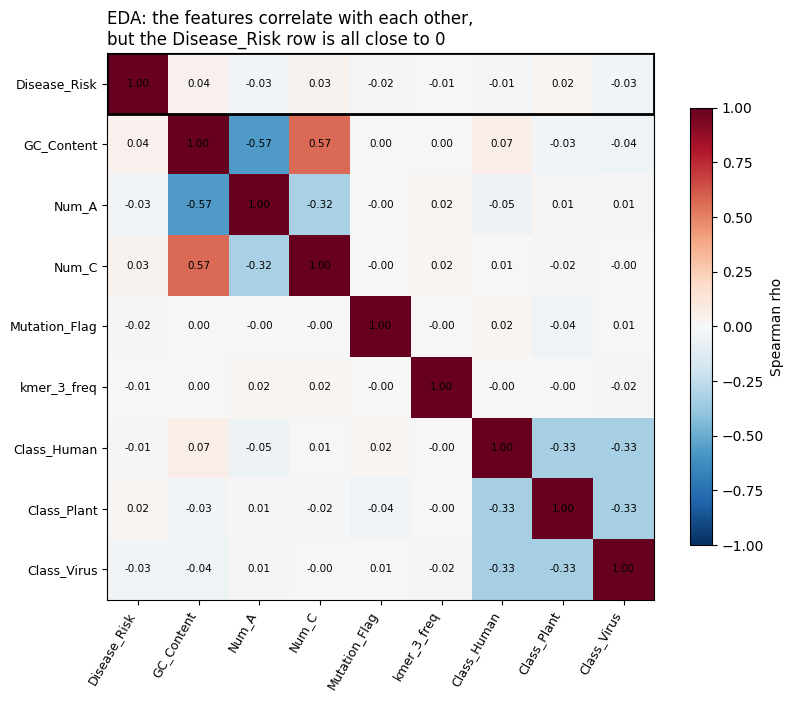

Largest |rho| with Disease_Risk: 0.045 (GC_Content), i.e. 0.20% of variance


In [27]:
eda_features = dna_data[["GC_Content", "Num_A", "Num_C", "Mutation_Flag", "kmer_3_freq"]].copy()
eda_features[["Class_Human", "Class_Plant", "Class_Virus"]] = pd.get_dummies(
    dna_data.Class_Label, dtype=float)[["Human", "Plant", "Virus"]]
eda_features.insert(0, "Disease_Risk", dna_data[TARGET].map({"Low": 1, "Medium": 2, "High": 3}))
correlation_matrix = eda_features.corr(method="spearman")
matrix_size = len(correlation_matrix)

figure, axis = plt.subplots(figsize=(8.5, 7))
heatmap = axis.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
figure.colorbar(heatmap, label="Spearman rho", shrink=0.8)
axis.set_xticks(range(matrix_size), correlation_matrix.columns, rotation=60, ha="right", fontsize=9)
axis.set_yticks(range(matrix_size), correlation_matrix.columns, fontsize=9)
for row_number, column_number in product(range(matrix_size), range(matrix_size)):
    axis.text(column_number, row_number, f"{correlation_matrix.iloc[row_number, column_number]:.2f}",
              ha="center", va="center", fontsize=7.5)
axis.add_patch(plt.Rectangle((-0.5, -0.5), matrix_size, 1, fill=False, edgecolor="black", lw=2))
axis.set_title("EDA: the features correlate with each other,\nbut the Disease_Risk row is all close to 0", loc="left")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "1_eda_correlation_matrix.png", dpi=150)
plt.show()

target_correlations = correlation_matrix.iloc[0, 1:]
print(f"Largest |rho| with Disease_Risk: {target_correlations.abs().max():.3f} ({target_correlations.abs().idxmax()}), "
      f"i.e. {target_correlations.abs().max() ** 2:.2%} of variance")

**PCA check:** do the three risk levels sit in different places when the 8 features are squeezed into 2 dimensions?

In [28]:
pca_coordinates = PCA(n_components=2, random_state=SEED).fit_transform(
    StandardScaler().fit_transform(eda_features.iloc[:, 1:]))
class_centres = (pd.DataFrame(pca_coordinates, columns=["PC1", "PC2"])
                 .groupby(risk_labels).mean().reindex(CLASS_ORDER_NATURAL))
display(class_centres.round(3))
centre_distances = [np.linalg.norm(class_centres.loc[first_class] - class_centres.loc[second_class])
                    for first_class, second_class in [("Low", "Medium"), ("Low", "High"), ("Medium", "High")]]
print(f"Largest distance between two class centres: {max(centre_distances):.3f} ")

,PC1,PC2
Low,-0.108,-0.038
Medium,0.047,-0.009
High,0.057,0.044


Largest distance between two class centres: 0.184 


**DNA-sequence tests:** does any 2-letter DNA word, or the base at any of the 100 positions, differ by risk level?

In [29]:
sequence_test_rows = []
for dinucleotide in ["".join(pair) for pair in product("ACGT", repeat=2)]:
    dinucleotide_counts = dna_data.Sequence.apply(
        lambda sequence: sum(sequence[start:start + 2] == dinucleotide for start in range(len(sequence) - 1)))
    sequence_test_rows.append({
        "test": f"dinucleotide {dinucleotide}",
        "p": stats.kruskal(*[dinucleotide_counts[risk_labels == risk_level]
                             for risk_level in CLASS_ORDER_SKLEARN]).pvalue})
base_matrix = np.array([list(sequence) for sequence in dna_data.Sequence])
for position in range(base_matrix.shape[1]):
    sequence_test_rows.append({
        "test": f"position {position + 1}",
        "p": stats.chi2_contingency(pd.crosstab(base_matrix[:, position], risk_labels), correction=False).pvalue})
sequence_tests = pd.DataFrame(sequence_test_rows)
sequence_tests["p_fdr"] = stats.false_discovery_control(sequence_tests.p)
print(f"{len(sequence_tests)} tests | raw p < 0.05: {int((sequence_tests.p < 0.05).sum())} "
      f"(about {0.05 * len(sequence_tests):.0f} expected by chance) | "
      f"significant after FDR: {int((sequence_tests.p_fdr < 0.05).sum())}")

116 tests | raw p < 0.05: 5 (about 6 expected by chance) | significant after FDR: 0


# Part 2 - Pre-processing

### 2A. Cleaning

In [30]:
cleaned_data = dna_data.drop(columns=["Sample_ID", "Sequence_Length", "AT_Content"])
cleaned_data.shape

(3000, 10)

### 2B. Encoding, feature selection and VIF check

In [31]:
features = cleaned_data[["GC_Content", "Num_A", "Num_C", "Mutation_Flag", "kmer_3_freq"]].astype(float)
features[["Class_Human", "Class_Plant", "Class_Virus"]] = pd.get_dummies(
    cleaned_data.Class_Label, dtype=float)[["Human", "Plant", "Virus"]]
features = features[SELECTED_FEATURES]
target = cleaned_data[TARGET].astype(str).values

variance_inflation = pd.Series(
    {feature_name: 1 / (1 - LinearRegression()
                        .fit(features.drop(columns=feature_name), features[feature_name])
                        .score(features.drop(columns=feature_name), features[feature_name]))
     for feature_name in features.columns},
    name="VIF")
print(f"13 columns -> {features.shape[1]} features; max VIF = {variance_inflation.max():.2f}")
variance_inflation.round(2).to_frame()

13 columns -> 8 features; max VIF = 2.06


,VIF
GC_Content,2.06
Num_A,1.53
Num_C,1.53
Mutation_Flag,1.00
kmer_3_freq,1.00
Class_Human,1.49
Class_Plant,1.49
Class_Virus,1.49


### 2C. Cross-validation scheme

In [32]:
outer_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(features, target))
inner_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Outer test-fold sizes:", [len(test_rows) for _, test_rows in outer_folds])

Outer test-fold sizes: [600, 600, 600, 600, 600]


# Part 3 - The models (nested 5-fold CV)

In [33]:
models = {
    "Majority baseline": (DummyClassifier(strategy="most_frequent"), {}),
    "Random guess": (DummyClassifier(strategy="stratified", random_state=SEED), {}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                      {"max_depth": [3, 5, None], "min_samples_leaf": [1, 10]}),
    "Logistic Regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                            {"logisticregression__C": [0.01, 0.1, 1, 10]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED, subsample=0.8),
                          {"n_estimators": [50, 100], "max_depth": [2, 3], "learning_rate": [0.05]}),
    "SVM": (make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
            {"svc__kernel": ["linear", "rbf"], "svc__C": [0.1, 1]}),
}

fold_results = []
out_of_fold_predictions = {model_name: np.empty(len(target), dtype=object) for model_name in models}
out_of_fold_probabilities = {model_name: np.zeros((len(target), 3)) for model_name in models}
for model_name, (model, parameter_grid) in models.items():
    print(f"tuning and testing {model_name} ...")
    for fold_number, (train_rows, test_rows) in enumerate(outer_folds, start=1):
        grid_search = GridSearchCV(model, parameter_grid, cv=inner_folds, scoring="accuracy", n_jobs=-1)
        grid_search.fit(features.iloc[train_rows], target[train_rows])
        best_model = grid_search.best_estimator_
        test_predictions = best_model.predict(features.iloc[test_rows])
        test_probabilities = best_model.predict_proba(features.iloc[test_rows])
        out_of_fold_predictions[model_name][test_rows] = test_predictions
        out_of_fold_probabilities[model_name][test_rows] = test_probabilities
        fold_results.append({
            "model": model_name,
            "fold": fold_number,
            "train_acc": accuracy_score(target[train_rows], best_model.predict(features.iloc[train_rows])),
            "test_acc": accuracy_score(target[test_rows], test_predictions),
            "macro_f1": f1_score(target[test_rows], test_predictions, average="macro",
                                 labels=CLASS_ORDER_SKLEARN, zero_division=0),
            "auc": roc_auc_score(target[test_rows], test_probabilities, multi_class="ovr",
                                 labels=CLASS_ORDER_SKLEARN),
            "recall_high": recall_score(target[test_rows], test_predictions, labels=["High"],
                                        average="macro", zero_division=0),
            "best_params": str(grid_search.best_params_)})
fold_results = pd.DataFrame(fold_results)

tuning and testing Majority baseline ...
tuning and testing Random guess ...
tuning and testing Random Forest ...
tuning and testing Logistic Regression ...
tuning and testing Gradient Boosting ...
tuning and testing SVM ...


### Model comparison (main results figure, Preetish)

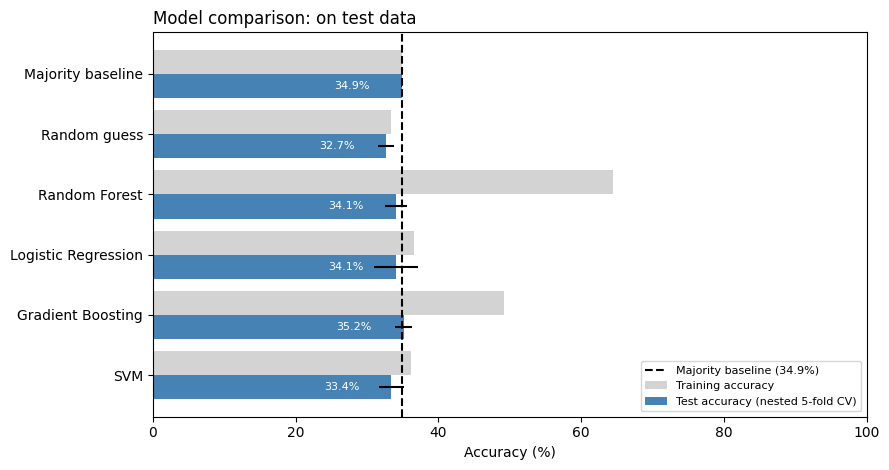

,model,train_acc,test_acc,test_sd,macro_f1,auc,recall_high,gap_vs_majority,overfit_gap
0,Majority baseline,0.349,0.349,0.001,0.172,0.500,1.000,-0.000,0.000
1,Random guess,0.334,0.327,0.011,0.327,0.495,0.330,-0.021,0.007
2,Random Forest,0.644,0.341,0.015,0.297,0.510,0.601,-0.008,0.304
3,Logistic Regression,0.365,0.341,0.031,0.326,0.509,0.513,-0.008,0.025
4,Gradient Boosting,0.492,0.352,0.012,0.333,0.516,0.558,0.003,0.141
5,SVM,0.361,0.334,0.018,0.236,0.492,0.774,-0.014,0.027


In [34]:
model_summary = (fold_results.groupby("model", sort=False)
                 .agg(train_acc=("train_acc", "mean"), test_acc=("test_acc", "mean"), test_sd=("test_acc", "std"),
                      macro_f1=("macro_f1", "mean"), auc=("auc", "mean"), recall_high=("recall_high", "mean"))
                 .reset_index())
model_summary["gap_vs_majority"] = model_summary.test_acc - majority_baseline
model_summary["overfit_gap"] = model_summary.train_acc - model_summary.test_acc

plot_data = model_summary.iloc[::-1]
bar_positions = np.arange(len(plot_data))
figure, axis = plt.subplots(figsize=(9, 4.8))
axis.barh(bar_positions + 0.2, plot_data.train_acc * 100, height=0.4, color="lightgray", label="Training accuracy")
axis.barh(bar_positions - 0.2, plot_data.test_acc * 100, height=0.4, xerr=plot_data.test_sd * 100,
          color="steelblue", label="Test accuracy (nested 5-fold CV)")
for bar_position, test_accuracy in zip(bar_positions, plot_data.test_acc * 100):
    axis.text(test_accuracy - 4.5, bar_position - 0.2, f"{test_accuracy:.1f}%",
              va="center", ha="right", fontsize=8, color="white")
axis.axvline(majority_baseline * 100, ls="--", color="black", label=f"Majority baseline ({majority_baseline:.1%})")
axis.set_yticks(bar_positions, plot_data.model)
axis.set_xlabel("Accuracy (%)")
axis.set_xlim(0, 100)
axis.legend(fontsize=8, loc="lower right")
axis.set_title("Model comparison: on test data", loc="left")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "2_model_comparison.png", dpi=150)
plt.show()
model_summary.round(3)

# Part 4 - Explaining the results
### 4A. What the Random Forest uses, and the learning curve

In [35]:
importance_per_fold = []
for train_rows, test_rows in outer_folds:
    forest = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=SEED, n_jobs=-1)
    forest.fit(features.iloc[train_rows], target[train_rows])
    fold_importance = permutation_importance(forest, features.iloc[test_rows], target[test_rows],
                                             n_repeats=10, random_state=SEED, n_jobs=-1)
    importance_per_fold.append(fold_importance.importances_mean)
permutation_importance_table = pd.DataFrame(
    {"mean_drop_in_accuracy_pts": np.mean(importance_per_fold, axis=0) * 100,
     "sd_pts": np.std(importance_per_fold, axis=0, ddof=1) * 100},
    index=features.columns).sort_values("mean_drop_in_accuracy_pts", ascending=False)
permutation_importance_table.round(2)

,mean_drop_in_accuracy_pts,sd_pts
Mutation_Flag,0.00,0.91
kmer_3_freq,-0.18,1.04
Class_Virus,-0.21,0.77
Num_A,-0.24,0.56
Num_C,-0.42,0.93
Class_Plant,-0.43,0.55
Class_Human,-0.73,0.89
GC_Content,-0.77,1.46


In [36]:
training_sizes, training_scores, test_scores = learning_curve(
    RandomForestClassifier(n_estimators=200, max_depth=5, random_state=SEED, n_jobs=-1),
    features, target, cv=outer_folds, train_sizes=np.linspace(0.1, 1.0, 6), scoring="accuracy", n_jobs=-1)
learning_curve_table = pd.DataFrame({"train_size": training_sizes,
                                     "train_acc": training_scores.mean(axis=1),
                                     "test_acc": test_scores.mean(axis=1),
                                     "test_sd": test_scores.std(axis=1)})
learning_curve_table.round(3)

,train_size,train_acc,test_acc,test_sd
0,240,0.817,0.333,0.023
1,672,0.648,0.340,0.025
2,1104,0.587,0.335,0.021
3,1536,0.559,0.339,0.014
4,1967,0.544,0.341,0.026
5,2400,0.507,0.328,0.011


### 4B. Logistic regression coefficients and confusion matrices

In [37]:
random_generator = np.random.default_rng(SEED)
scaled_features = StandardScaler().fit_transform(features)
bootstrap_coefficients = []
for _ in range(200):
    resampled_rows = random_generator.integers(0, len(target), len(target))
    bootstrap_model = LogisticRegression(C=1, max_iter=5000).fit(scaled_features[resampled_rows], target[resampled_rows])
    bootstrap_coefficients.append(bootstrap_model.coef_)
bootstrap_coefficients = np.array(bootstrap_coefficients)

coefficient_rows = []
for class_index, class_name in enumerate(CLASS_ORDER_SKLEARN):
    for feature_index, feature_name in enumerate(features.columns):
        coefficient_samples = bootstrap_coefficients[:, class_index, feature_index]
        coefficient_rows.append({"class": class_name,
                                 "feature": feature_name,
                                 "coef_mean": coefficient_samples.mean(),
                                 "ci_low": np.percentile(coefficient_samples, 2.5),
                                 "ci_high": np.percentile(coefficient_samples, 97.5)})
coefficient_table = pd.DataFrame(coefficient_rows)
coefficient_table["excludes_zero"] = (coefficient_table.ci_low > 0) | (coefficient_table.ci_high < 0)
print(f"Largest |coefficient| = {coefficient_table.coef_mean.abs().max():.3f} log-odds per SD | "
      f"{int(coefficient_table.excludes_zero.sum())} of {len(coefficient_table)} intervals exclude zero "
      f"(about {0.05 * len(coefficient_table):.1f} expected by chance)")

Largest |coefficient| = 0.071 log-odds per SD | 2 of 24 intervals exclude zero (about 1.2 expected by chance)


In [38]:
trained_model_names = ["Random Forest", "Logistic Regression", "Gradient Boosting", "SVM"]
class_recalls = {}
for model_name in trained_model_names:
    confusion_table = pd.DataFrame(
        confusion_matrix(target, out_of_fold_predictions[model_name], labels=CLASS_ORDER_NATURAL),
        index=[f"true {risk_level}" for risk_level in CLASS_ORDER_NATURAL],
        columns=[f"pred {risk_level}" for risk_level in CLASS_ORDER_NATURAL])
    print(f"\n{model_name}")
    display(confusion_table)
    class_recalls[model_name] = recall_score(target, out_of_fold_predictions[model_name],
                                             labels=CLASS_ORDER_NATURAL, average=None)
recall_table = pd.DataFrame(class_recalls, index=[f"recall_{risk_level}" for risk_level in CLASS_ORDER_NATURAL]).T
recall_table.round(2)


Random Forest


,pred Low,pred Medium,pred High
true Low,237,141,600
true Medium,218,156,602
true High,239,178,629



Logistic Regression


,pred Low,pred Medium,pred High
true Low,286,195,497
true Medium,264,199,513
true High,273,236,537



Gradient Boosting


,pred Low,pred Medium,pred High
true Low,228,219,531
true Medium,218,243,515
true High,228,234,584



SVM


,pred Low,pred Medium,pred High
true Low,141,53,784
true Medium,142,52,782
true High,175,61,810


,recall_Low,recall_Medium,recall_High
Random Forest,0.24,0.16,0.60
Logistic Regression,0.29,0.20,0.51
Gradient Boosting,0.23,0.25,0.56
SVM,0.14,0.05,0.77


### 4C. ROC AUC and permutation test

In [39]:
auc_values = {}
for model_name in trained_model_names:
    auc_values[model_name] = [roc_auc_score(target == risk_level, out_of_fold_probabilities[model_name][:, class_index])
                              for class_index, risk_level in enumerate(CLASS_ORDER_SKLEARN)]
auc_table = pd.DataFrame(auc_values, index=[f"AUC {risk_level} vs rest" for risk_level in CLASS_ORDER_SKLEARN]).T
auc_table.round(3)

,AUC High vs rest,AUC Low vs rest,AUC Medium vs rest
Random Forest,0.489,0.509,0.515
Logistic Regression,0.501,0.516,0.502
Gradient Boosting,0.509,0.516,0.517
SVM,0.494,0.488,0.492


In [40]:
real_label_score, shuffled_label_scores, permutation_p_value = permutation_test_score(
    make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)),
    features, target, cv=outer_folds, n_permutations=200, random_state=SEED, n_jobs=-1)
print(f"Real labels: {real_label_score:.1%} | shuffled labels: mean {shuffled_label_scores.mean():.1%} "
      f"(95% of runs below {np.percentile(shuffled_label_scores, 95):.1%}) | "
      f"permutation p = {permutation_p_value:.2f}")

Real labels: 34.0% | shuffled labels: mean 33.4% (95% of runs below 34.8%) | permutation p = 0.32


### 4D. Sanity check: is the code broken, or the data?

In [41]:
random_generator = np.random.default_rng(SEED)
planted_labels = pd.qcut(dna_data.GC_Content.rank(method="first"), 3,
                         labels=["Low", "Medium", "High"]).astype(str).values
noisy_rows = random_generator.random(len(planted_labels)) < 0.15
planted_labels[noisy_rows] = random_generator.choice(["Low", "Medium", "High"], noisy_rows.sum())
planted_baseline = max(Counter(planted_labels).values()) / len(planted_labels)

sanity_rows = []
for model_name in trained_model_names:
    model, parameter_grid = models[model_name]
    first_settings = {setting_name: setting_values[0] for setting_name, setting_values in parameter_grid.items()}
    planted_model = clone(model).set_params(**first_settings)
    planted_accuracy = cross_val_score(planted_model, features, planted_labels, cv=outer_folds, n_jobs=-1).mean()
    sanity_rows.append({"check": "Planted label (GC thirds + 15% noise)",
                        "model": model_name,
                        "accuracy": planted_accuracy,
                        "majority_baseline": planted_baseline})
sanity_checks = pd.DataFrame(sanity_rows)
sanity_checks.round(3)

,check,model,accuracy,majority_baseline
0,Planted label (GC thirds + 15% noise),Random Forest,0.864,0.344
1,Planted label (GC thirds + 15% noise),Logistic Regression,0.801,0.344
2,Planted label (GC thirds + 15% noise),Gradient Boosting,0.861,0.344
3,Planted label (GC thirds + 15% noise),SVM,0.854,0.344


In [42]:
model_lines = [f"  {row.model:<20} test {row.test_acc:.1%} (sd {row.test_sd:.1%}), train {row.train_acc:.1%}, "
               f"AUC {row.auc:.3f}, macro-F1 {row.macro_f1:.3f}, vs baseline {row.gap_vs_majority * 100:+.1f} pts"
               for row in model_summary.itertuples()]
verdict_lines = [
    "WHY ACCURACY STAYS AT THE BASELINE",
    "=" * 40,
    f"Majority baseline (always 'High'): {majority_baseline:.1%}",
    "",
    "Model results (nested 5-fold CV):",
    *model_lines,
    "",
    f"Amit:     {int(dna_data.isna().sum().sum())} missing values, {int(dna_data.duplicated().sum())} duplicates; "
    f"target ~1/3 each (p = {balance_test.pvalue:.2f}); learning curve flat "
    f"({learning_curve_table.test_acc.iloc[0]:.1%} -> {learning_curve_table.test_acc.iloc[-1]:.1%}).",
    f"Manju:    Class_Label p = {categorical_tests.p[0]:.2f} (V = {categorical_tests.cramers_v[0]:.3f}), "
    f"Mutation_Flag p = {categorical_tests.p[1]:.2f} (V = {categorical_tests.cramers_v[1]:.3f}); "
    f"max VIF = {variance_inflation.max():.2f}; {int(coefficient_table.excludes_zero.sum())} of "
    f"{len(coefficient_table)} coefficient CIs exclude zero.",
    f"Soha:     {int((numeric_tests.kruskal_p_fdr < 0.05).sum())} of {len(numeric_tests)} numeric features significant "
    f"after FDR; max MI {numeric_tests.mutual_info_bits.max():.4f} bits; kmer_3_freq looks uniform random; "
    f"AUC {auc_table.values.min():.2f}-{auc_table.values.max():.2f}; permutation p = {permutation_p_value:.2f}.",
    f"Preetish: max |rho| with target {target_correlations.abs().max():.3f}; "
    f"{int((sequence_tests.p_fdr < 0.05).sum())} of {len(sequence_tests)} sequence tests significant after FDR; "
    f"planted label {sanity_checks.accuracy.min():.1%}-{sanity_checks.accuracy.max():.1%}."
]
print("\n".join(verdict_lines))

WHY ACCURACY STAYS AT THE BASELINE
Majority baseline (always 'High'): 34.9%

Model results (nested 5-fold CV):
  Majority baseline    test 34.9% (sd 0.1%), train 34.9%, AUC 0.500, macro-F1 0.172, vs baseline -0.0 pts
  Random guess         test 32.7% (sd 1.1%), train 33.4%, AUC 0.495, macro-F1 0.327, vs baseline -2.1 pts
  Random Forest        test 34.1% (sd 1.5%), train 64.4%, AUC 0.510, macro-F1 0.297, vs baseline -0.8 pts
  Logistic Regression  test 34.1% (sd 3.1%), train 36.5%, AUC 0.509, macro-F1 0.326, vs baseline -0.8 pts
  Gradient Boosting    test 35.2% (sd 1.2%), train 49.2%, AUC 0.516, macro-F1 0.333, vs baseline +0.3 pts
  SVM                  test 33.4% (sd 1.8%), train 36.1%, AUC 0.492, macro-F1 0.236, vs baseline -1.4 pts

Amit:     0 missing values, 0 duplicates; target ~1/3 each (p = 0.20); learning curve flat (33.3% -> 32.8%).
Manju:    Class_Label p = 0.31 (V = 0.035), Mutation_Flag p = 0.70 (V = 0.015); max VIF = 2.06; 2 of 24 coefficient CIs exclude zero.
Soha:    